In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.tri as tri
import sys
sys.path.insert(0, '../../../src/')
import DoubleLayerWithHoles as DL
from matplotlib import path
from matplotlib import cm, ticker
import scipy as sc
import Geometries as geo

In [2]:
inside_solution = pd.read_csv('EigenvaluesEigenvectorsInsideSol_Dahne_MPI.csv', low_memory=False) 

In [3]:
inside_solution

,Eigenvalues,Eigenvectors0,Inside0,Inside1,Solution0,Eigenvalues.1,Eigenvectors0.1,Inside0.1,Inside1.1,Solution0.1,...,Inside0.2,Inside1.2,Solution0.2,Eigenvalues_higher_precision,Eigenvectors_higher_precision0,Inside_higher_precision0,Inside_higher_precision1,Solution_higher_precision0,nodal_line0,nodal_line1
0,(2.4332559642443345-6.499637331631472e-12j),(-0.00016367117680484523+3.38993135653663e-05j),0.00000,-1.99875,(5.729591618859878e-07+5.527317659446642e-07j),(3.8253821084541553-1.466107350384597e-08j),(-0.009477748497958+0.010569972938429177j),0.00000,-1.99875,(6.306747756712645e-05+6.155188416015825e-05j),...,0.00000,-1.99875,(1.3528736690585986e-05-1.613904599779203e-05j),(3.8253821084541553-1.466107350384597e-08j),(-0.009477748497958+0.010569972938429177j),-0.157304,-1.992522,(6.3684985840585e-05+6.243092448167745e-05j),-0.314609,-0.603307
1,NaN,(-0.00016046225433997564+4.0991039317719525e-05j),-0.41000,-1.94750,(3.5371805691562766e-06+3.4262690425492296e-06j),NaN,(-0.009572222435760834+0.010704424317778983j),-0.41000,-1.94750,(0.0004632884748054281+0.00045294424018830527j),...,-0.41000,-1.94750,(5.7592164032138106e-05-0.00010193086553958084j),(3.8277282002988353-8.714909872180107e-07j),(-0.009572222435760834+0.010704424317778983j),-0.148565,-1.992522,(9.742156850233363e-05+9.461117845299162e-05j),-0.315548,-0.603000
2,NaN,(-0.00015339642621878466+5.652403992675836e-05j),-0.35875,-1.94750,(7.496270964823205e-06+7.2342360991642455e-06j),NaN,(-0.009776776011341949+0.010999218280582427j),-0.35875,-1.94750,(0.0009472850273187648+0.0009246541844006133j),...,-0.35875,-1.94750,(0.0001298884664821889-0.00021377424810991013j),NaN,(-0.009776776011341949+0.010999218280582427j),-0.139826,-1.992522,(0.0001293609064135972+0.00012495108914930587j),-0.323348,-0.600377
3,NaN,(-0.00014767550796051217+6.902055486269058e-05j),-0.30750,-1.94750,(1.1312281560583265e-05+1.0900143375190539e-05j),NaN,(-0.009939302707889114+0.011236386350293634j),-0.30750,-1.94750,(0.0013817910190678183+0.0013478345622041782j),...,-0.30750,-1.94750,(0.0002064527442042338-0.0003193322519379118j),NaN,(-0.009939302707889114+0.011236386350293634j),-0.131087,-1.992522,(0.00015939417071345312+0.00015364533833385832j),-0.332087,-0.596711
4,NaN,(-0.00013556369939318725+9.52474490322049e-05j),-0.25625,-1.94750,(1.489542344430748e-05+1.4367124993182193e-05j),NaN,(-0.010274462686765453+0.011734194833737359j),-0.25625,-1.94750,(0.0017607391612136695+0.0017182555950024329j),...,-0.25625,-1.94750,(0.0002843084969274389-0.00041583506054874053j),NaN,(-0.010274462686765453+0.011734194833737359j),-0.122348,-1.992522,(0.00018691263239694602+0.00018201826965818027j),-0.336913,-0.594261
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149356,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.122348,1.992522,(0.00018691437754031828+0.00018201409477653155j),NaN,NaN
149357,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.131087,1.992522,(0.00015939587446209182+0.0001536415413616113j),NaN,NaN
149358,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.139826,1.992522,(0.00012936257401080856+0.0001249476940518076j),NaN,NaN
149359,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.148565,1.992522,(9.742319503194341e-05+9.460821276259176e-05j),NaN,NaN


In [4]:
xy_inside = inside_solution[['Inside0', 'Inside1']]
xy_inside = xy_inside.dropna(how="any")
xy_inside = xy_inside.to_numpy(dtype=float).T

In [5]:
sol = inside_solution['Solution0']
sol = sol.dropna(how="any")
sol = sol.to_numpy(dtype=np.complex128)

In [6]:
faces = np.array([55,55,55,55,55])
n = 2*faces
alpha = (1-np.sqrt(3/5))/2

a_big_ell = 2
b_big_ell = 2
xm_big_ell = 0
ym_big_ell = 0
rot_big_ell = 0
n_ellipses = 6

# Parameters for the inner ellpses
a_small_ell = 0.15592081791325
b_small_ell = 0.39189243830382
distance_small_ell = 1.07828534328197
angles_small_ell = np.linspace(0,2*np.pi, n_ellipses, endpoint=False)
xm_small_ell = distance_small_ell*np.cos(angles_small_ell)
ym_small_ell = distance_small_ell*np.sin(angles_small_ell)
rot_small_ell = angles_small_ell

# Parameters for the inner hypotrochoid
xa_hyp = 0.6
xi_hyp = 0.5
A_hyp = n_ellipses
r_hyp = (xa_hyp+xi_hyp)/(2*(A_hyp-1))
R_hyp = A_hyp*r_hyp
a_hyp = (A_hyp-1)*(xa_hyp-xi_hyp)/(xa_hyp+xi_hyp)
xm_hyp = 0
ym_hyp = 0
rot_hyp = 0

vi, collocation_nodes = geo.create_6_ellipses(a_big_ell,b_big_ell,0,0,0,a_small_ell,b_small_ell,distance_small_ell,n_ellipses,n[0],alpha)


In [7]:
hypotrochoid = DL.create_hypotrochoid(R_hyp,r_hyp,a_hyp,xm_hyp,ym_hyp,rot_hyp,n[0])

In [8]:
vi_closed_curve = np.dstack((vi,vi[:,:,0:1]))

In [9]:
hypotrochoid_closed_curve =  np.hstack((hypotrochoid,hypotrochoid[:,-2:-1]))

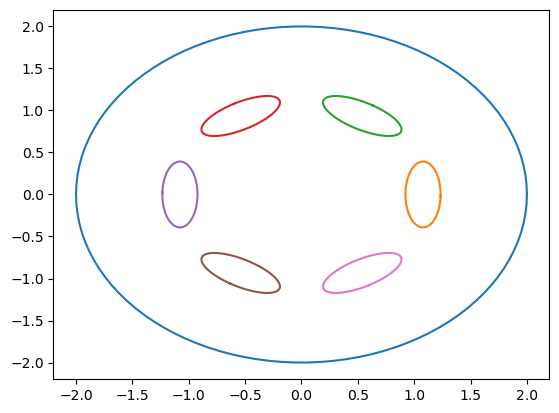

In [10]:
for i in range(vi_closed_curve.shape[0]):
    plt.plot(vi_closed_curve[i][0,:], vi_closed_curve[i][1,:])

In [11]:
def ray_tracing_in_holes(boundary, xmid, ymid, radius):
    """
    Routine to find all the points of a square on an equidistant grid, that lie within the given domain without the given holes.

    Parameters
    ----------
    boundary : numpy.ndarray
        Array containing the vertices and midpoints for each of the approximated boundaries.
    xmid : numpy.ndarray
        x-Positions of all points that should be checked to be inside the given domain without holes.
    ymid : numpy.ndarray
        y-Positions of all points that should be checked to be inside the given domain without holes.
    radius : float
        Adds or subtracts a margin around a path to make the enclosed area slightly larger or smaller.

    Returns
    -------
    xy_inside : numpy.ndarray
        Numpy array containing all points that lie inside of the given domain without the holes.
    """
    # Create a path for the boundary of the holes
    p = [path.Path(boundary[i].T) for i in range(boundary.shape[0])]    
    # Create the mesh of the square to be checked, whether they are inside or outside of the domain with holes.
    mesh = np.stack((xmid,ymid),axis = 1)
    # Check whether the mesh is inside or outside of the outer boundary of the domain (without holes).
    inside = np.array([p[i].contains_points(mesh,radius=radius) for i in range(boundary.shape[0])])
    inside_any = np.any(inside, axis=0)
    return inside_any

In [12]:
eigenvalues = inside_solution['Eigenvalues'][0]
eigenvalues

'(2.4332559642443345-6.499637331631472e-12j)'

In [13]:
(2.4332559642443345-6.499637331631472e-12j) * (2.4332559642443345-6.499637331631472e-12j)

(5.920734587530626-3.1630562605234825e-11j)

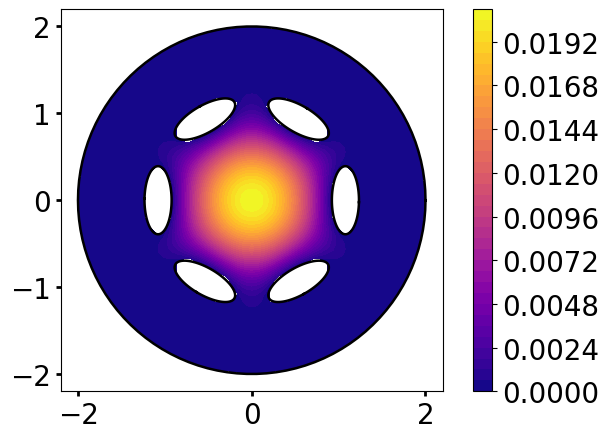

In [14]:
x_inside = xy_inside[0,:]
y_inside = xy_inside[1,:]
real_sol = np.real(sol)
vmin_sol=np.sort(real_sol)[0]
vmax_sol=np.sort(real_sol)[-1]
# Triangulation
triang = tri.Triangulation(x_inside, y_inside)

# Mask
xmid = x_inside[triang.triangles].mean(axis=1)
ymid = y_inside[triang.triangles].mean(axis=1)
mask1 = ray_tracing_in_holes(np.array([vi_closed_curve[0]]), xmid, ymid, 0.0)
mask2 = ray_tracing_in_holes(np.array([vi_closed_curve[1]]), xmid, ymid, 0.0)
mask3 = ray_tracing_in_holes(np.array([vi_closed_curve[2]]), xmid, ymid, 0.0)
mask4 = ray_tracing_in_holes(np.array([vi_closed_curve[3]]), xmid, ymid, 0.0)
mask5 = ray_tracing_in_holes(np.array([vi_closed_curve[4]]), xmid, ymid, 0.0)
mask6 = ray_tracing_in_holes(np.array([vi_closed_curve[5]]), xmid, ymid, 0.0)
mask7 = ray_tracing_in_holes(np.array([vi_closed_curve[6]]), xmid, ymid, 0.0)

mask1_inv = ~mask1
mask = mask1_inv | mask2 | mask3 | mask4 | mask5 | mask6 | mask7
triang.set_mask(mask)

# Kontur-Plot
plt.rcParams.update({'font.size':20})
plt.tick_params(axis='both', width=2)
plt.tricontourf(triang, real_sol, cmap='plasma',levels= 40, vmin=vmin_sol, vmax=vmax_sol)
cbar = plt.colorbar()
cbar.ax.tick_params(labelsize=20)
plt.tricontour(triang, real_sol, colors='black', levels = [0], linestyles = 'dashed', linewidths = 1.8)

for i in range(n_ellipses+1):
    plt.plot(vi_closed_curve[i][0,:], vi_closed_curve[i][1,:], color='black', linewidth = 1.8)

plt.xlim(-2.05,2.05)
plt.ylim(-2.05,2.05)

plt.axis('square')

plt.tight_layout()
plt.show()

In [15]:
eigenvalues = inside_solution['Eigenvalues.1'][0]
eigenvalues

'(3.8253821084541553-1.466107350384597e-08j)'

In [16]:
eigenvalues = inside_solution['Eigenvalues_higher_precision'][0]
eigenvalues

'(3.8253821084541553-1.466107350384597e-08j)'

In [17]:
(3.8253821084541553-1.466107350384597e-08j)*(3.8253821084541553-1.466107350384597e-08j)

(14.633548275681159-1.1216841654468729e-07j)

In [18]:
xy_inside = inside_solution[['Inside_higher_precision0', 'Inside_higher_precision1']]
xy_inside = xy_inside.dropna(how="any")
xy_inside = xy_inside.to_numpy(dtype=float).T

In [19]:
sol = inside_solution['Solution_higher_precision0']
sol = sol.dropna(how="any")
sol = sol.to_numpy(dtype=np.complex128)

In [20]:
big_ellipse = DL.create_ellipse(a_big_ell,b_big_ell,xm_big_ell,ym_big_ell,rot_big_ell,n[0])

In [21]:
small_ellipses = np.array([np.flip(DL.create_ellipse(a_small_ell,b_small_ell,xm_small_ell[i],ym_small_ell[i],rot_small_ell[i],n[0]),1) for i in range(n_ellipses)])

In [22]:
radius = 0.01

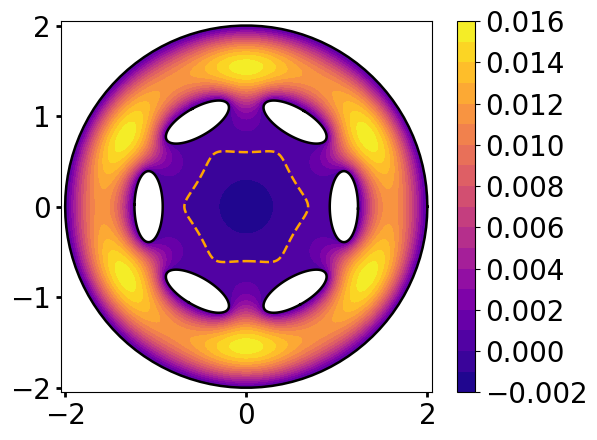

In [31]:
x_inside = xy_inside[0,:]
y_inside = xy_inside[1,:]
real_sol = np.real(sol)

big_ellipse_append = np.concatenate((big_ellipse, big_ellipse[:,0].reshape(2,1)), axis=1)
small_ellipses_append = np.concatenate((small_ellipses, small_ellipses[:,:,0].reshape(small_ellipses.shape[0],2,1)), axis=2)

vmin_sol=np.sort(real_sol)[0]
vmax_sol=np.sort(real_sol)[-1]

# Triangulation
triang = tri.Triangulation(x_inside, y_inside)

# Mask
x_boundary = x_inside[triang.triangles]
y_boundary = y_inside[triang.triangles]
x_boundary_flatten = x_boundary.flatten()
y_boundary_flatten = y_boundary.flatten()
xmid = x_inside[triang.triangles].mean(axis=1)
ymid = y_inside[triang.triangles].mean(axis=1)

mask1_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[0]]), x_boundary_flatten, y_boundary_flatten, 0.01)
mask2_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[1]]), x_boundary_flatten, y_boundary_flatten, -0.01)
mask3_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[2]]), x_boundary_flatten, y_boundary_flatten, -0.01)
mask4_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[3]]), x_boundary_flatten, y_boundary_flatten, -0.01)
mask5_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[4]]), x_boundary_flatten, y_boundary_flatten, -0.01)
mask6_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[5]]), x_boundary_flatten, y_boundary_flatten, -0.01)
mask7_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[6]]), x_boundary_flatten, y_boundary_flatten, -0.01)

mask1_reshape = mask1_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask2_reshape = mask2_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask3_reshape = mask3_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask4_reshape = mask4_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask5_reshape = mask5_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask6_reshape = mask6_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask7_reshape = mask7_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask1_boundary = mask1_reshape.any(axis=0)
mask2_boundary = mask2_reshape.any(axis=0)
mask3_boundary = mask3_reshape.any(axis=0)
mask4_boundary = mask4_reshape.any(axis=0)
mask5_boundary = mask5_reshape.any(axis=0)
mask6_boundary = mask6_reshape.any(axis=0)
mask7_boundary = mask7_reshape.any(axis=0)

mask1 = ray_tracing_in_holes(np.array([vi_closed_curve[0]]), xmid, ymid, 0.01)
mask2 = ray_tracing_in_holes(np.array([vi_closed_curve[1]]), xmid, ymid, -0.01)
mask3 = ray_tracing_in_holes(np.array([vi_closed_curve[2]]), xmid, ymid, -0.01)
mask4 = ray_tracing_in_holes(np.array([vi_closed_curve[3]]), xmid, ymid, -0.01)
mask5 = ray_tracing_in_holes(np.array([vi_closed_curve[4]]), xmid, ymid, -0.01)
mask6 = ray_tracing_in_holes(np.array([vi_closed_curve[5]]), xmid, ymid, -0.01)
mask7 = ray_tracing_in_holes(np.array([vi_closed_curve[6]]), xmid, ymid, -0.01)

mask1_inv = ~mask1
mask1_inv_boundary = ~mask1_boundary
mask = mask1_inv | mask2 | mask3 | mask4 | mask5 | mask6 | mask7 | mask1_inv_boundary |  mask2_boundary | mask3_boundary | mask4_boundary | mask5_boundary | mask6_boundary | mask7_boundary
triang.set_mask(mask)
# Kontur-Plot
plt.rcParams.update({'font.size':20})
plt.tick_params(axis='both', width=2)
cf = plt.tricontourf(triang, real_sol, cmap='plasma',levels= 19)
cf1 = plt.tricontour(triang, real_sol, colors='orange', levels = [0], linestyles = 'dashed', linewidths = 1.8)

plt.plot(big_ellipse_append[0,:], big_ellipse_append[1,:], 'black', linewidth = 1.8)
for i in range(n_ellipses):
    plt.plot(small_ellipses_append[i][0,:], small_ellipses_append[i][1,:], 'black', linewidth = 1.8)

plt.axis('square')

plt.xlim(-2.05,2.05)
plt.ylim(-2.05,2.05)

cbar = plt.colorbar(cf, label='')
cbar.ax.tick_params(labelsize=20)

plt.tight_layout()

plt.savefig('circle_six_ellipses_end_result_lower_resolution.eps', format="eps")
plt.show()

In [24]:
import matplotlib.colors as mcolors

# Erstelle eine benutzerdefinierte Colormap
def custom_colormap():
    # Definiere die Grenzen für die Colormap
    bounds = [-0.01, 0, 0.1]
    # Erstelle eine Colormap basierend auf 'plasma'
    cmap = plt.get_cmap('plasma', len(bounds) - 1)
    
    # Erstelle eine normierte Colormap für logarithmische Skalierung
    norm = mcolors.BoundaryNorm(bounds, cmap.N)
    
    return cmap, norm

In [25]:
vmin_sol

np.float64(-0.0351017630392341)

In [26]:
vmin_sol

np.float64(-0.0351017630392341)

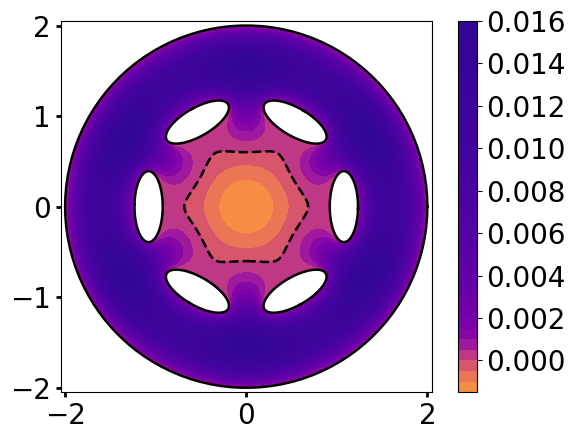

In [36]:
linthresh = 0.001 # Der Schwellenwert für die logarithmische Skalierung
norm = mcolors.SymLogNorm(linthresh=linthresh, vmin=vmin_sol, vmax=-vmin_sol)

fig, ax = plt.subplots()
plt.rcParams.update({'font.size':20})
ax.tick_params(axis='both', width=2)
cf = plt.tricontourf(triang, real_sol, cmap='plasma_r', norm=norm ,levels= 40, vmin=vmin_sol)
plt.tricontour(triang, real_sol, colors='black', levels = [0], linestyles = 'dashed', linewidths = 1.8)


plt.axis('square')
cbar = plt.colorbar(cf, label='')
cbar.ax.tick_params(labelsize=20)

plt.xlim(-2.05,2.05)
plt.ylim(-2.05,2.05)
for i in range(n_ellipses+1):
    plt.plot(vi_closed_curve[i][0,:], vi_closed_curve[i][1,:], color='black', linewidth = 1.8)

plt.tight_layout()

plt.savefig('circle_six_ellipses_end_result_symlognorm_lower_resolution.eps', format="eps")
plt.show()

In [28]:
eigenvalues = inside_solution['Eigenvalues.2'][0]
eigenvalues

'(3.8277282002988353-8.714909872180107e-07j)'

In [29]:
(3.8277282002988353-8.714909872180107e-07j) * (3.8277282002988353-8.714909872180107e-07j)

(14.651503175362201-6.671661256161302e-06j)

In [30]:
xy_inside = inside_solution[['Inside0.2', 'Inside1.2']]
xy_inside = xy_inside.dropna(how="any")
xy_inside = xy_inside.to_numpy(dtype=float).T

In [31]:
sol = inside_solution['Solution0.2']
sol = sol.dropna(how="any")
sol = sol.to_numpy(dtype=np.complex128)

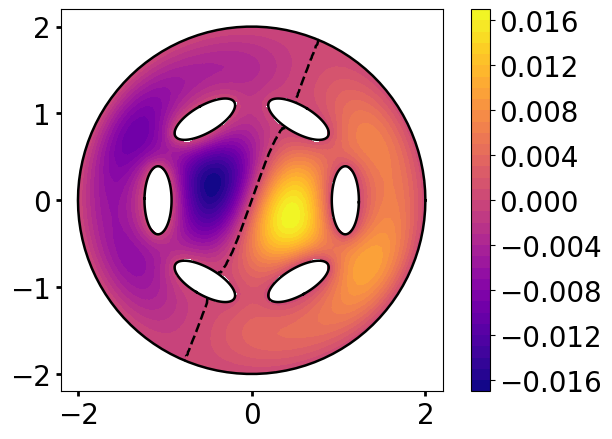

In [32]:
x_inside = xy_inside[0,:]
y_inside = xy_inside[1,:]
real_sol = np.real(sol)
vmin_sol=np.sort(real_sol)[0]
vmax_sol=np.sort(real_sol)[-1]
# Triangulation
triang = tri.Triangulation(x_inside, y_inside)

# Mask
xmid = x_inside[triang.triangles].mean(axis=1)
ymid = y_inside[triang.triangles].mean(axis=1)
mask1 = ray_tracing_in_holes(np.array([vi_closed_curve[0]]), xmid, ymid, 0.)
mask2 = ray_tracing_in_holes(np.array([vi_closed_curve[1]]), xmid, ymid, -0.)
mask3 = ray_tracing_in_holes(np.array([vi_closed_curve[2]]), xmid, ymid, -0.)
mask4 = ray_tracing_in_holes(np.array([vi_closed_curve[3]]), xmid, ymid, -0.)
mask5 = ray_tracing_in_holes(np.array([vi_closed_curve[4]]), xmid, ymid, -0.)
mask6 = ray_tracing_in_holes(np.array([vi_closed_curve[5]]), xmid, ymid, -0.)
mask7 = ray_tracing_in_holes(np.array([vi_closed_curve[6]]), xmid, ymid, -0.)

mask1_inv = ~mask1
mask = mask1_inv | mask2 | mask3 | mask4 | mask5 | mask6 | mask7
triang.set_mask(mask)

# Kontur-Plot
plt.rcParams.update({'font.size':20})
plt.tick_params(axis='both', width=2)
plt.tricontourf(triang, real_sol, cmap='plasma',levels= 40, vmin=vmin_sol, vmax=vmax_sol)
cbar = plt.colorbar()
cbar.ax.tick_params(labelsize=20)
plt.tricontour(triang, real_sol, colors='black', levels = [0], linestyles = 'dashed', linewidths = 1.8)

for i in range(n_ellipses+1):
    plt.plot(vi_closed_curve[i][0,:], vi_closed_curve[i][1,:], color='black', linewidth = 1.8)

plt.xlim(-2.05,2.05)
plt.ylim(-2.05,2.05)

plt.axis('square')
plt.tight_layout()
plt.show()

In [33]:
(3.571335  -1.39811351e-08j)* (3.571335  -1.39811351e-08j)

(12.754433682224999-9.9862634244717e-08j)

In [34]:
(3.571335-1.33237017e-08j)*(3.571335-1.33237017e-08j)

(12.754433682224999-9.5166804421539e-08j)

In [35]:
(3.76253437 -1.74979258e-07j)*(3.76253437 -1.74979258e-07j)

(14.156664885431267-1.3167309445241949e-06j)

In [36]:
(14.156664885431267-1.3167309445241949e-06j) - (12.754433682224999-9.9862634244717e-08j)

(1.4022312032062683-1.2168683102794779e-06j)

In [37]:
(14.156664885431267-1.3167309445241949e-06j) - (12.754433682224999-9.5166804421539e-08j)

(1.4022312032062683-1.221564140102656e-06j)

In [38]:
(3.57133505 -1.33219138e-08j)*(3.57133505 -1.33219138e-08j)

(12.754434039358504-9.515403537403739e-08j)

In [39]:
(3.57133505 -1.38640962e-08j) * (3.57133505 -1.38640962e-08j)

(12.754434039358504-9.902666539126362e-08j)

In [40]:
(3.76253442 -1.7497928e-07j)* (3.76253442 -1.7497928e-07j)

(14.156665261684708-1.3167311275736352e-06j)

In [41]:
14.15666526 - 12.75443404

1.4022312200000009

In [42]:
(3.57133502 -1.32689773e-08j) * (3.57133502 -1.32689773e-08j)

(12.754433825078399-9.477592662215009e-08j)

In [43]:
(3.57133502 -1.30660822e-08j) * (3.57133502 -1.30660822e-08j)

(12.754433825078399-9.332671387011729e-08j)

In [44]:
(3.76253441-1.74979255e-07j) * (3.76253441-1.74979255e-07j)

(14.156665186434019-1.3167309359473292e-06j)

In [45]:
14.15666519 - 12.75443383

1.40223136

In [46]:
(3.57133494-1.29742698e-08j) * (3.57133494-1.29742698e-08j)

(12.754433253664802-9.267092611545361e-08j)

In [47]:
(3.57133494-1.34980969e-08j) * (3.57133494-1.34980969e-08j)

(12.754433253664802-9.641245016495138e-08j)

In [48]:
(3.76253443-1.74979279e-07j) * (3.76253443-1.74979279e-07j)

(14.156665336935395-1.316731123548152e-06j)

In [49]:
14.15666534 - 12.75443325

1.40223209

In [50]:
(3.8253957 -2.15425746e-07j) * (3.8253957 -2.15425746e-07j)

(14.633652261578444-1.6481774448353844e-06j)

In [51]:
(3.82488287-2.15113596e-07j) * (3.82488287-2.15113596e-07j)

(14.629728969219391-1.6455686168890011e-06j)

In [52]:
14.63365226 - 14.62972897

0.003923289999999469

In [53]:
(3.82539575-2.14164932e-07j) * (3.82539575-2.14164932e-07j)

(14.633652644118017-1.6385312413436781e-06j)

In [54]:
( 3.82488291-2.15113585e-07j) * ( 3.82488291-2.15113585e-07j)

(14.629729275210021-1.6455685499506648e-06j)

In [55]:
14.63365264 - 14.62972928

0.003923359999999931

In [56]:
(3.82539574-2.1492657e-07j) * (3.82539574-2.1492657e-07j)

(14.6336525676101-1.6443583705816235e-06j)

In [57]:
(3.8248829-2.15113594e-07j) * (3.8248829-2.15113594e-07j)

(14.629729198712363-1.6455686144962853e-06j)

In [58]:
14.63365257 - 14.6297292

0.003923370000000759

In [59]:
(3.82539576-2.14192069e-07j) * (3.82539576-2.14192069e-07j)

(14.633652720625932-1.638738865156455e-06j)

In [60]:
(3.82488292-2.15113574e-07j) * (3.82488292-2.15113574e-07j)

(14.62972935170768-1.645568470105512e-06j)

In [61]:
14.63365272- 14.62972935

0.003923370000000759

In [62]:
(3.81167299-2.10102042e-07j) * (3.81167299-2.10102042e-07j)

(14.528850982695495-1.6016805572704912e-06j)

In [63]:
(3.81117763-2.10153951e-07j) * (3.81117763-2.10153951e-07j)

(14.525074927412373-1.6018680738146322e-06j)

In [64]:
14.52885098 - 14.52507493

0.0037760499999990316